# ¿Qué formas locales se repiten en el caso con quiebres?

**Pregunta:** ¿Podemos identificar ventanas repetidas sin confundir sus posiciones originales con un eje visual reducido? Esta lección sigue el caso de quiebres estructurales desde sus observaciones completas hasta un perfil matricial, un par de motivos y límites candidatos. La pregunta trata sobre similitud de formas locales. No pregunta si un valor extraño es peligroso, si un límite demuestra un cambio del generador ni si un detector en línea habría podido emitir una alarma en esa posición.

## Objetivos

Conserve el inicio de ventana sobre el eje original, distinga distancia de forma y amplitud, y examine un perfil independiente. Explique por qué solicitar una cantidad de regímenes no equivale a descubrir cambios verdaderos.

## Preparación

Cree un entorno aislado e instale las dependencias exactas que aparecen a continuación. Estas versiones identifican el entorno numérico de las salidas comprometidas. La lección lee el pequeño artefacto admitido y ejecuta sus propios diagnósticos; no descarga el corpus completo ni requiere un checkpoint. Mantenga juntas la secuencia original y sus posiciones al comparar las ventanas calculadas con los datos del gráfico.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0


In [1]:
# Configure a portable session and suppress only the known repeated-shape control warning.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.analysis.sequence import matrix_profile, sequence_report
from chronoscopelab.analysis.sequence import multiscale_entropy, time_reversal
from chronoscopelab.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Datos

El artefacto admitido conserva la identidad y las observaciones utilizadas a continuación.


In [2]:
# Read every original observation from the admitted structural-break case.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print("Original observations:", len(values))


Original observations: 300


## Método

El caso contiene trescientas observaciones originales. Una ventana de veinticuatro observaciones avanza de una en una y produce 277 inicios. Cada ventana se centra y divide por su propia desviación poblacional antes de medir la distancia. Por ello, dos ventanas pueden compartir una forma normalizada aunque sus niveles absolutos sean distintos. Un cambio de nivel no constituye automáticamente una discordancia de forma; aplicar un umbral de amplitud respondería otra pregunta.


In [3]:
# Calculate the exact normalized self-join and retain original window positions.
profile = matrix_profile(values, window=24)
print("Window:", profile["window"])
print("Profile starts:", len(profile["profile"]))
print("Motif pairs:", profile["motifs"])
print("Discord windows:", profile["discords"])


Window: 24
Profile starts: 277
Motif pairs: [{'start': 112, 'match': 232, 'distance': 1.9284087073398055}]
Discord windows: [{'start': 187, 'distance': 4.961150848844531}, {'start': 97, 'distance': 4.664855917535791}, {'start': 26, 'distance': 2.690089967466322}]


La comparación excluye coincidencias triviales dentro de un radio de seis inicios. Sin esa exclusión, una ventana podría elegirse a sí misma o escoger una copia desplazada con gran superposición, produciendo una distancia engañosamente pequeña. El par de motivos exige además ventanas separadas. Las discordancias candidatas corresponden a grandes distancias al vecino más cercano, con sus ventanas de consulta separadas entre sí. Este ordenamiento es descriptivo: la distancia no lleva asociada una probabilidad calibrada de falsa alarma.


In [4]:
# Compare the product adapter with the pinned STUMPY reference.
import stumpy
reference = stumpy.stump(values, m=24)
difference = np.max(np.abs(np.asarray(profile["profile"])-reference.P_))
print("Maximum distance from reference:", f"{difference:.8f}")


Maximum distance from reference: 0.00000000


La llamada independiente a la biblioteca expone el mismo perfil exacto de distancias. La concordancia comprueba la extracción del adaptador sobre un caso real del producto; la prueba exhaustiva pequeña del repositorio aporta otro oráculo numérico. La lección no sustituye esa prueba por una afirmación sobre una imagen atractiva. Examine el vector de distancias y los índices enteros cuando evalúe si dos intervalos destacados corresponden realmente a las observaciones esperadas.


In [5]:
# Run the complete sequence diagnostic with an explicit candidate period.
diagnostics = sequence_report(values, seasonality=12)
print("Original index count:", len(diagnostics["observation_indices"]))
print("FLUSS candidates:", diagnostics["matrix_profile"]["regime_boundaries"])


Original index count: 300
FLUSS candidates: [104, 239]


FLUSS lee los arcos entre vecinos y construye una curva corregida. El producto solicita tres regímenes candidatos y comunica sus límites internos. Recibe una cantidad, no los puntos de quiebre conocidos del generador. Esta diferencia importa: la cantidad solicitada no debe presentarse como una estimación del número de cambios verdaderos. Los límites usan la secuencia completa, por lo que describen un análisis retrospectivo y no información disponible en un origen anterior de predicción.

Una ventana de doce observaciones permite examinar sensibilidad a la escala local declarada. Es una comparación diagnóstica, no una búsqueda de anotaciones favorables.


In [6]:
# Compare a fixed shorter window without selecting a favorable result.
short_profile = matrix_profile(values, window=12)
print("Short-window motif pair:", short_profile["motifs"])
print("Short-window candidate boundaries:", short_profile["regime_boundaries"])


Short-window motif pair: [{'start': 14, 'match': 134, 'distance': 0.7937109471393579}]
Short-window candidate boundaries: [248, 276]


### Sensibilidad a la longitud de ventana

Sea $z_i(k)$ la observación $k$ de la ventana que empieza en $i$, centrada y escalada con los valores de esa ventana. Para ventanas no constantes, el perfil en el inicio $i$ es

$$
P_m(i)=\min_{|i-j|>\lceil m/4\rceil}
\sqrt{\sum_{k=0}^{m-1}(z_i(k)-z_j(k))^2}.
$$

Cada distancia suma $m$ diferencias al cuadrado. La figura divide $P_m$ por $\sqrt m$, de modo que el eje vertical mide la raíz cuadrática media del desacuerdo por observación normalizada. Ambas curvas usan los índices originales de inicio. Los vecinos elegibles cambian, porque otra ventana modifica la forma observada, el radio de exclusión y el número de ventanas completas que caben hasta el final.


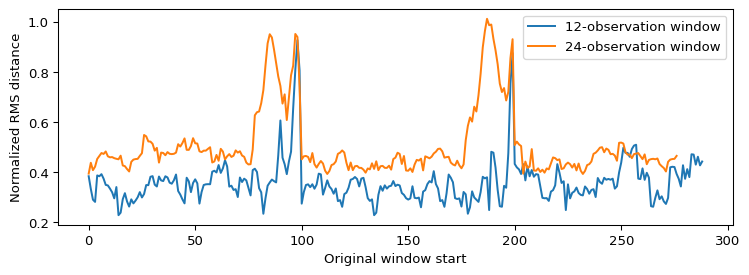

In [7]:
# Compare window distances after dividing each by the square root of its length.
fig, ax = plt.subplots()
for result in (short_profile, profile):
    window = result["window"]
    rms = np.asarray(result["profile"]) / np.sqrt(window)
    ax.plot(np.arange(len(rms)), rms, label=f"{window}-observation window")
ax.set(xlabel="Original window start", ylabel="Normalized RMS distance")
ax.legend()
fig.tight_layout()
plt.show()


Interprete diferencias grandes entre curvas como sensibilidad a la representación. Cuando un mínimo cambia de posición, inspeccione los dos intervalos originales emparejados y pregunte si un fragmento de un patrón largo se repite en otro tramo. Cuando cambia un máximo, examine si la ventana larga cruza un cambio de nivel. Ese movimiento no decide cuál ventana conviene. En datos operativos, elija una duración a partir de la acción, por ejemplo detectar una hora recurrente de funcionamiento. Fije la escala, la segmentación y la política de faltantes antes de evaluar en una serie reservada. Para detectar en línea, en cada instante utilice solo ventanas ya disponibles. Un patrón retrospectivo puede confirmarse después del evento que interesa, por lo que es necesario registrar el límite de información.

Guarde el índice del vecino junto con la distancia. Una distancia numérica pequeña por sí sola no identifica los dos intervalos originales que el lector debe comparar.

## Resultados

**Respuesta:** Las ventanas del par de motivos comienzan en 112 y 232 sobre el eje original. FLUSS propone límites en 104 y 239 para los tres regímenes solicitados. Los candidatos describen formas observadas; sus posiciones no establecen rupturas conocidas del generador ni una alarma prospectiva.


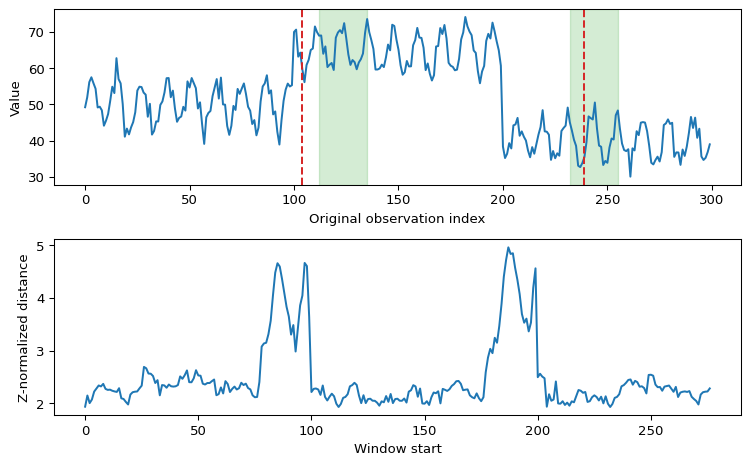

In [8]:
# Connect motif intervals and retrospective boundaries to original observations.
fig, axes = plt.subplots(2, 1, figsize=(8, 5))
axes[0].plot(values, label="original observations")
for boundary in profile["regime_boundaries"]:
    axes[0].axvline(boundary, color="tab:red", linestyle="--")
for motif in profile["motifs"]:
    for start in (motif["start"], motif["match"]):
        axes[0].axvspan(start, start+23, color="tab:green", alpha=.2)
axes[0].set(xlabel="Original observation index", ylabel="Value")
axes[1].plot(profile["profile"], label="nearest-shape distance")
axes[1].set(xlabel="Window start", ylabel="Z-normalized distance")
fig.tight_layout()
plt.show()


El panel superior conserva el eje original y muestra los intervalos de motivos sobre los valores brutos. El panel inferior asigna una distancia a cada inicio de ventana; su último índice es menor que el último índice de la secuencia. Lea el ancho del intervalo antes de asociar una característica del perfil con un punto superior. Un mínimo identifica un vecino elegible cercano; un máximo señala una ventana cuyo mejor vecino disponible resulta relativamente distante bajo la normalización declarada.

Respuesta: las ventanas de veinticuatro observaciones generan 277 posiciones del perfil a partir de 300 observaciones originales. Los registros impresos de motivos y discordancias indican las ubicaciones candidatas de esta ejecución, y la diferencia respecto a la biblioteca comprueba su fuente numérica. Esto permite describir formas repetidas de manera reproducible. No establece que una discordancia haya causado un error de pronóstico ni que FLUSS encuentre todos los cambios de nivel. Otra longitud definiría otros patrones locales y exigiría una comparación descrita por separado.

### Limitaciones

La normalización elimina deliberadamente información de media y escala. Un valor absoluto infrecuente puede tener una coincidencia de forma ordinaria, mientras que un patrón frecuente puede aparecer en un nivel importante para una decisión. Las ventanas casi constantes requieren la convención declarada por la biblioteca. Una secuencia totalmente constante se presenta como no disponible porque no discrimina formas. Las anotaciones y tablas de ventanas de la app conservan esas diferencias sin transformar las posiciones en una precisión aparente.

## Resumen

Una ventana es un intervalo con normalización y exclusión declaradas. Posiciones originales, distancias de referencia y límites retrospectivos permiten examinar la afirmación sobre patrones.

### Reproducir

Ejecute el cuaderno completo en el entorno fijado. Compare los inicios impresos con el artefacto admitido y revise las pruebas de distancias exhaustivas y transición plantada. No sustituya las observaciones originales por una trayectoria diezmada: hacerlo cambiaría las formas locales y las unidades de la longitud de ventana.

## Referencias

[Tutorial de perfil exacto de STUMPY](https://stumpy.readthedocs.io/en/latest/Tutorial_STUMPY_Basics.html).

Yeh y colaboradores, Matrix Profile I, DOI 10.1109/ICDM.2016.0179. Gharghabi y colaboradores, Matrix Profile VIII, DOI 10.1109/ICDM.2017.21. Los tutoriales STUMPY documentan normalización, exclusión y segmentación candidata.
